# Comparing elastic and plastic multilayer indentation models

This notebook uses the bundled Au/Ti/SiO₂/Si continuous-stiffness indentation data to compare (1) the NIMS three-film Mercier elastic-compliance model, which fits the top-film modulus, and (2) hardness estimates from load and contact stiffness using Saha- and Mercier-style relations.

**Scope:** NIMS's MATLAB `model_multilayer_plastic.m` is a hardness-estimation workflow, not a nonlinear plastic finite-element constitutive model. It prepares multilayer geometry, obtains elastic properties, and then estimates film hardness from indentation load/stiffness. The current MATLAB function calls `model_bilayer_elastic`, so the Python three-layer elastic input below is a transparent comparison workflow, not an exact reproduction of every MATLAB GUI result.

Run from the repository root or this notebook's folder. Requirements: Python 3, NumPy, SciPy, and Matplotlib. Lengths are nm, load is mN, stiffness is mN/nm, and moduli/hardness are GPa. Lower-layer and substrate properties are assumed known; a single indentation curve cannot independently identify every layer.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import least_squares

cwd = Path.cwd().resolve()
root = next((p for p in (cwd, *cwd.parents)
             if (p / 'data_indentation').is_dir()
             and (p / 'matlab_code').is_dir()), None)
if root is None:
    raise FileNotFoundError('Start Jupyter in the NIMS repository or one of its subdirectories.')
data_file = root / 'data_indentation' / 'MTS_3films_Au-Ti-SiO2-Si_CSM-1nm.txt'
if not data_file.is_file():
    raise FileNotFoundError(f'Indentation data not found: {data_file}')
print('Repository:', root)

Repository: C:\github\NIMS


## Inputs and measured contact quantities

Layer order is bottom-to-top: SiO₂, Ti, Au. The Au modulus is unknown and fitted; the other elastic properties and thicknesses are example assumptions aligned with `notebooks/multilayer_indentation.ipynb`. The CSM correction and area-function settings are instrument/calibration dependent: change them only to match the experiment.

In [2]:
depth_min_nm, depth_max_nm = 60.0, 360.0
substrate = {'name': 'Si', 'E_GPa': 165.0, 'nu': 0.28}
films = [
    {'name': 'SiO2', 'thickness_nm': 500.0, 'E_GPa': 70.0, 'nu': 0.18},
    {'name': 'Ti', 'thickness_nm': 500.0, 'E_GPa': 120.0, 'nu': 0.34},
    {'name': 'Au', 'thickness_nm': 500.0, 'E_GPa': None, 'nu': 0.32},
]
indenter_E_GPa, indenter_nu = 1070.0, 0.07
beta = 1.034
area_coefficients = [24.56, 0, 0, 0, 0, 0, 0, 0, 0]
area_powers = [2, 1, 1/2, 1/4, 1/8, 1/16, 1/32, 1/64, 1/128]
tip_defect_nm = 1.0
loubet_alpha = 1.24
apply_csm_correction = True
csm_k, csm_m = 0.757, 1.38
thickness_correction_factor = 0.3

raw = np.loadtxt(data_file, ndmin=2)
if raw.shape[1] != 6 or not np.isfinite(raw).all():
    raise ValueError('Expected six finite columns: depth, depth SD, load, load SD, stiffness, stiffness SD.')
if not 0 <= depth_min_nm < depth_max_nm:
    raise ValueError('Depth limits must be nonnegative and increasing.')
raw = raw[:np.argmax(raw[:, 2]) + 1]
selected = raw[(raw[:, 0] > depth_min_nm) & (raw[:, 0] < depth_max_nm)]
if len(selected) < 4:
    raise ValueError('At least four loading samples must lie in the depth interval.')
depth, depth_sd, load, load_sd, stiffness_N_m, stiffness_sd = selected.T
stiffness = stiffness_N_m * 1e-6  # N/m -> mN/nm
if np.any(load <= 0) or np.any(stiffness <= 0):
    raise ValueError('Selected load and stiffness must be positive.')
if apply_csm_correction:
    if np.any(depth_sd <= 0) or csm_k <= 0 or csm_m <= 0:
        raise ValueError('CSM correction requires positive depth SD and correction constants.')
    peak_load = load.max()
    radicand = 1 - 2 * np.sqrt(2) * depth_sd * stiffness / peak_load
    if np.any(radicand < 0):
        raise ValueError('CSM correction is not real for the selected samples.')
    stiffness = ((1 / np.sqrt(2 * np.pi)) * (1 / csm_k) ** (1 / csm_m)
                 * (1 - radicand ** (1 / csm_m)) * peak_load / depth_sd)
    depth = depth + np.sqrt(2) * depth_sd
    load = load + np.sqrt(2) * load_sd
contact_depth = loubet_alpha * (depth + tip_defect_nm - load / stiffness)
if np.any(~np.isfinite(contact_depth) | (contact_depth <= 0)):
    raise ValueError('Contact depth must be positive and finite; check data and calibration.')
if len(area_coefficients) != len(area_powers):
    raise ValueError('Area coefficients and powers must have the same length.')
area = sum(c * contact_depth ** p for c, p in zip(area_coefficients, area_powers))
if np.any(~np.isfinite(area) | (area <= 0)):
    raise ValueError('Calculated contact area must be positive and finite.')
radius = np.sqrt(area / np.pi)
sample_hardness = 1e6 * load / area  # mN/nm^2 -> GPa
print(f'{len(depth)} loading samples selected; contact depth {contact_depth.min():.1f}–{contact_depth.max():.1f} nm')

21 loading samples selected; contact depth 76.2–389.1 nm


## Elastic multilayer model: fit the top-film modulus

The Mercier model treats the contact response as a sum of elastic compliances from each layer and the substrate. For three films, NIMS uses contact radii shifted through the layer stack and fits the unknown top-film reduced modulus to the measured sample reduced modulus. This identifies an elastic modulus response; it does not predict plastic flow or hardness.

In [3]:
def reduced_modulus(young_GPa, poisson):
    if not np.isfinite(young_GPa) or young_GPa <= 0 or not -1 < poisson < 0.5:
        raise ValueError('Young modulus must be positive and Poisson ratio must be between -1 and 0.5.')
    return young_GPa / (1 - poisson ** 2)

def multilayer_terms(contact_radius, contact_depth_nm):
    a = np.asarray(contact_radius, dtype=float)
    hc = np.asarray(contact_depth_nm, dtype=float)
    if len(films) not in (2, 3) or a.shape != hc.shape:
        raise ValueError('Use two or three films and matching contact-radius/depth arrays.')
    lower_compliance = np.zeros_like(a)
    top_coefficient = None
    for index in range(len(films) - 1, -1, -1):
        layer = films[index]
        nominal = layer['thickness_nm']
        thickness = nominal - thickness_correction_factor * hc if index == len(films) - 1 else nominal
        if nominal <= 0 or np.any(thickness <= 0):
            raise ValueError('Layer thicknesses and corrected top-film thickness must stay positive.')
        coefficient = thickness / (np.pi * a ** 2 + 2 * a * thickness)
        if index == len(films) - 1:
            top_coefficient = coefficient
        else:
            lower_compliance += coefficient / reduced_modulus(layer['E_GPa'], layer['nu'])
        a = a + 2 * nominal / np.pi
    substrate_reduced = reduced_modulus(substrate['E_GPa'], substrate['nu'])
    lower_compliance += 1 / (2 * a * substrate_reduced)
    return top_coefficient, lower_compliance

def composite_reduced_modulus(top_reduced_GPa, contact_radius, top_coefficient, lower_compliance):
    return 1 / (2 * contact_radius * (top_coefficient / top_reduced_GPa + lower_compliance))

# Retain NIMS's legacy elastic indenter reduction convention for this fit.
indenter_reduced_for_elastic_fit = reduced_modulus(indenter_E_GPa, indenter_nu ** 2)
effective_reduced_modulus = np.sqrt(np.pi) * 1e6 * stiffness / (2 * beta * np.sqrt(area))
sample_compliance = 1 / effective_reduced_modulus - 1 / indenter_reduced_for_elastic_fit
if np.any(~np.isfinite(sample_compliance) | (sample_compliance <= 0)):
    raise ValueError('Invalid sample reduced modulus; review calibration and depth range.')
sample_reduced_modulus = 1 / sample_compliance
top_coefficient, lower_compliance = multilayer_terms(radius, contact_depth)
fit = least_squares(
    lambda p: composite_reduced_modulus(p[0], radius, top_coefficient, lower_compliance)
              - sample_reduced_modulus,
    [100.0], bounds=(1e-6, 1000.0),
)
if not fit.success:
    raise RuntimeError(f'Multilayer modulus fit failed: {fit.message}')
fitted_top_reduced = fit.x[0]
fitted_top_young = fitted_top_reduced * (1 - films[-1]['nu'] ** 2)
fitted_composite = composite_reduced_modulus(
    fitted_top_reduced, radius, top_coefficient, lower_compliance)
inverse_film_compliance = 1 / (2 * radius * sample_reduced_modulus) - lower_compliance
valid_film = np.isfinite(inverse_film_compliance) & (inverse_film_compliance > 0)
film_reduced_modulus = np.full_like(sample_reduced_modulus, np.nan)
film_reduced_modulus[valid_film] = top_coefficient[valid_film] / inverse_film_compliance[valid_film]
if not np.any(valid_film):
    raise ValueError('No physical pointwise top-film modulus estimates remain.')
print(f"Fitted Au Young modulus: {fitted_top_young:.2f} GPa")
print(f"Fit RMSE: {np.sqrt(np.mean(fit.fun ** 2)):.3f} GPa")

Fitted Au Young modulus: 93.61 GPa
Fit RMSE: 1.391 GPa


## Plastic/hardness workflow: estimate film hardness

The measured composite hardness is $P/A$. The Saha relation estimates hardness from load, stiffness, and an effective reduced modulus; NIMS's Saha implementation uses a sample/composite modulus, while its Mercier implementation uses a film modulus. Here those inputs are respectively the measured multilayer sample modulus and the pointwise top-film modulus from the three-layer elastic inversion.

The MATLAB hardness functions combine `Eind_red` with moduli in GPa using `Eind_red * 1e-3`; `indenter_properties.m` produces `Eind_red` from an indenter modulus expressed in Pa in the GUI path. That conversion is not a consistent Pa-to-GPa conversion. To avoid silently mixing units, the Python curves below use dimensionally consistent GPa throughout; they are method comparisons, not bit-for-bit MATLAB output. Neither hardness relation is a stress-strain plasticity simulation.

In [4]:
indenter_reduced_GPa = reduced_modulus(indenter_E_GPa, indenter_nu)
effective_for_saha = 1 / (1 / sample_reduced_modulus + 1 / indenter_reduced_GPa)
effective_for_mercier = 1 / (1 / film_reduced_modulus + 1 / indenter_reduced_GPa)
hardness_factor = beta ** 2 * (4 / np.pi) * load / (1e6 * stiffness ** 2)
hardness_saha = hardness_factor * effective_for_saha ** 2
hardness_mercier = hardness_factor * effective_for_mercier ** 2
if not np.any(np.isfinite(hardness_saha)) or not np.any(np.isfinite(hardness_mercier)):
    raise ValueError('Hardness estimates are non-finite; check inputs and units.')
print(f'Mean composite hardness P/A: {np.mean(sample_hardness):.2f} GPa')
print(f'Mean Saha-style film estimate: {np.nanmean(hardness_saha):.2f} GPa')
print(f'Mean Mercier-style film estimate: {np.nanmean(hardness_mercier):.2f} GPa')
print(f'Fitted Au elastic modulus: {fitted_top_young:.2f} GPa')

Mean composite hardness P/A: 2.19 GPa
Mean Saha-style film estimate: 2.19 GPa
Mean Mercier-style film estimate: 1.53 GPa
Fitted Au elastic modulus: 93.61 GPa


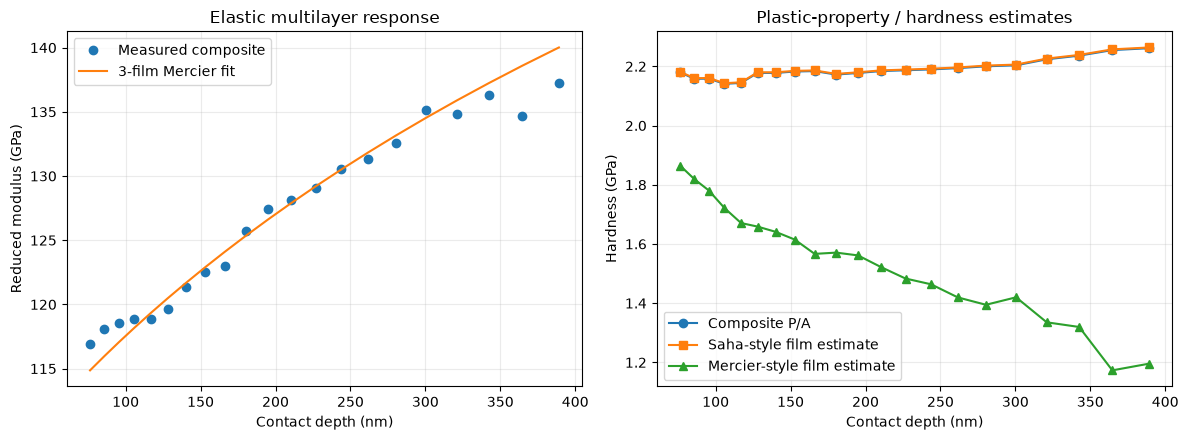

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(contact_depth, sample_reduced_modulus, 'o', label='Measured composite')
axes[0].plot(contact_depth, fitted_composite, '-', label='3-film Mercier fit')
axes[0].set(xlabel='Contact depth (nm)', ylabel='Reduced modulus (GPa)',
            title='Elastic multilayer response')
axes[0].legend()
axes[0].grid(alpha=0.25)
axes[1].plot(contact_depth, sample_hardness, 'o-', label='Composite P/A')
axes[1].plot(contact_depth, hardness_saha, 's-', label='Saha-style film estimate')
axes[1].plot(contact_depth, hardness_mercier, '^-', label='Mercier-style film estimate')
axes[1].set(xlabel='Contact depth (nm)', ylabel='Hardness (GPa)',
            title='Plastic-property / hardness estimates')
axes[1].legend()
axes[1].grid(alpha=0.25)
fig.tight_layout()
plt.show()

In [6]:
comparison = [
    ('Elastic fit', 'Au Young modulus', fitted_top_young, 'GPa'),
    ('Plastic estimate', 'Composite hardness P/A', float(np.mean(sample_hardness)), 'GPa'),
    ('Plastic estimate', 'Saha-style film hardness', float(np.nanmean(hardness_saha)), 'GPa'),
    ('Plastic estimate', 'Mercier-style film hardness', float(np.nanmean(hardness_mercier)), 'GPa'),
]
print(f"{'Workflow':<20} {'Result':<32} {'Mean':>10}  Unit")
print('-' * 78)
for workflow, name, value, unit in comparison:
    print(f'{workflow:<20} {name:<32} {value:>10.3f}  {unit}')
assert np.isfinite(fitted_top_young) and fitted_top_young > 0
assert np.all(np.isfinite(fitted_composite) & (fitted_composite > 0))
assert np.all(np.isfinite(sample_hardness) & (sample_hardness > 0))
print('\nSanity checks passed: fitted moduli and measured hardness are finite and positive.')

Workflow             Result                                 Mean  Unit
------------------------------------------------------------------------------
Elastic fit          Au Young modulus                     93.611  GPa
Plastic estimate     Composite hardness P/A                2.190  GPa
Plastic estimate     Saha-style film hardness              2.192  GPa
Plastic estimate     Mercier-style film hardness           1.533  GPa

Sanity checks passed: fitted moduli and measured hardness are finite and positive.


## Interpretation and limitations

- **Elastic model:** predicts the depth-dependent composite reduced modulus from elastic compliance and estimates the unknown Au modulus, conditional on known Ti/SiO₂/Si properties and the thickness/correction model.
- **Plastic-property workflow:** reports composite hardness from $P/A$ and estimates film hardness from load/stiffness with a selected reduced-modulus input. These values depend on contact-area calibration, pile-up/sink-in, and substrate influence; they are not yield stress or a constitutive stress-strain curve.
- The observed data do not independently identify every layer's modulus or hardness. Vary assumed lower-layer properties and calibration settings to assess sensitivity; use independent tests or a validated FEM model for stronger inference.
- The elastic fit retains the NIMS legacy indenter Poisson-ratio convention. The hardness comparison uses a dimensionally consistent indenter modulus, intentionally differing from the MATLAB `1e-3` factor described above.

Project sources: [`model_multilayer_elastic.m`](../matlab_code/model_multilayer_elastic.m), [`model_mercier_3layers.m`](../matlab_code/elastic_models/model_mercier_3layers.m), [`model_multilayer_plastic.m`](../matlab_code/model_multilayer_plastic.m), [`model_saha.m`](../matlab_code/plastic_models/model_saha.m), [`model_mercier.m`](../matlab_code/plastic_models/model_mercier.m), and [thin-film model documentation](../docs/models_thin_films.rst).